####Name: Piyush Vohra
####Section-Batch: B1 - B3
####Roll No: 45

**Title: Global Resource Pressure and Population Intelligence System**

**Practical 1: Data Collection (Web Scraping)**

In [1]:
import requests
import pandas as pd

In [2]:
indicators = {
    "SP.POP.TOTL": "Population",
    "SP.POP.GROW": "Population_Growth",
    "EN.POP.DNST": "Population_Density",
    "SP.URB.TOTL.IN.ZS": "Urban_Population",
    "EG.ELC.ACCS.ZS": "Electricity_Access",
    "SH.H2O.BASW.ZS": "Water_Access"
}

In [3]:
def get_indicator(code):

    url = f"https://api.worldbank.org/v2/country/all/indicator/{code}"

    params = {
        "format": "json",
        "date": "2000:2024",
        "per_page": 20000
    }

    data = requests.get(url, params=params).json()

    return data[1]

In [4]:
# Actual Website -> https://data.worldbank.org/indicator/SP.POP.TOTL

# Page Source didn't gave HTML code directly, therefore fetched it using it's API

In [5]:
all_data = []

for code, name in indicators.items():

    data = get_indicator(code)

    for row in data:
        all_data.append({
            "Country": row["country"]["value"],
            "Country_Code": row["countryiso3code"],
            "Year": row["date"],
            "Indicator": name,
            "Value": row["value"]
        })

In [6]:
df = pd.DataFrame(all_data)

df.head()

,Country,Country_Code,Year,Indicator,Value
0,Africa Eastern and Southern,AFE,2024,Population,769280888.0
1,Africa Eastern and Southern,AFE,2023,Population,750491370.0
2,Africa Eastern and Southern,AFE,2022,Population,731821393.0
3,Africa Eastern and Southern,AFE,2021,Population,713090928.0
4,Africa Eastern and Southern,AFE,2020,Population,694446100.0


In [7]:
df = df.pivot_table(
    index=["Country", "Country_Code", "Year"],
    columns="Indicator",
    values="Value"
).reset_index()

In [8]:
df.head()

Indicator,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966
1,Afghanistan,AFG,2001,9.3,20284307.0,31.099929,0.762005,18.741238,29.762926
2,Afghanistan,AFG,2002,14.1,21378117.0,32.776961,5.252030,18.941248,31.836077
3,Afghanistan,AFG,2003,19.0,22733049.0,34.854344,6.145194,19.160035,33.908629
4,Afghanistan,AFG,2004,23.8,23560654.0,36.123230,3.575835,19.399359,35.999355


In [9]:
df = df[df["Country_Code"].str.len() == 3]

df.head()

Indicator,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966
1,Afghanistan,AFG,2001,9.3,20284307.0,31.099929,0.762005,18.741238,29.762926
2,Afghanistan,AFG,2002,14.1,21378117.0,32.776961,5.252030,18.941248,31.836077
3,Afghanistan,AFG,2003,19.0,22733049.0,34.854344,6.145194,19.160035,33.908629
4,Afghanistan,AFG,2004,23.8,23560654.0,36.123230,3.575835,19.399359,35.999355


In [10]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of records: 6525
Number of columns: 9


In [11]:
df.to_csv("worldbank_population_resources_raw.csv", index=False)

print("Raw dataset saved successfully!")

Raw dataset saved successfully!


**Practical 2: Data Preprocessing & Exploratory Data Analysis**

In [12]:
print("Shape:", df.shape)

df.head()

Shape: (6525, 9)


Indicator,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966
1,Afghanistan,AFG,2001,9.3,20284307.0,31.099929,0.762005,18.741238,29.762926
2,Afghanistan,AFG,2002,14.1,21378117.0,32.776961,5.252030,18.941248,31.836077
3,Afghanistan,AFG,2003,19.0,22733049.0,34.854344,6.145194,19.160035,33.908629
4,Afghanistan,AFG,2004,23.8,23560654.0,36.123230,3.575835,19.399359,35.999355


In [13]:
df["Year"] = pd.to_numeric(df["Year"])

In [14]:
df.isnull().sum()

,0
Indicator,
Country,0
Country_Code,0
Year,0
Electricity_Access,75
Population,0
Population_Density,142
Population_Growth,1
Urban_Population,0
Water_Access,227


In [15]:
important_cols = [
    "Population",
    "Population_Growth",
    "Population_Density",
    "Urban_Population",
    "Electricity_Access",
    "Water_Access"
]

In [16]:
for col in important_cols:
    df[col] = df.groupby("Country")[col].transform(
        lambda x: x.fillna(x.median())
    )

In [17]:
df.isnull().sum()

,0
Indicator,
Country,0
Country_Code,0
Year,0
Electricity_Access,50
Population,0
Population_Density,25
Population_Growth,0
Urban_Population,0
Water_Access,75


In [18]:
df = df.dropna(subset=important_cols)

print("Records after cleaning:", len(df))

Records after cleaning: 6425


In [19]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [20]:
df = df.drop_duplicates()

In [21]:
df.describe()

Indicator,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access
count,6425.000000,6425.000000,6.425000e+03,6425.000000,6425.000000,6425.000000,6425.000000
mean,2012.000000,80.954828,2.713317e+08,355.546661,1.321377,58.291988,86.147213
std,7.211664,28.156659,8.922339e+08,1724.455948,1.506602,23.052028,17.347114
min,2000.000000,0.800000,9.544000e+03,0.136492,-11.356645,8.043814,18.759061
25%,2006.000000,67.400000,1.463495e+06,33.821365,0.413436,39.537519,80.019211
50%,2012.000000,98.000000,9.745953e+06,75.460432,1.205872,58.170915,93.903310
75%,2018.000000,100.000000,5.264071e+07,175.253333,2.238488,76.889258,99.026618
max,2024.000000,100.000000,8.140898e+09,21530.000000,21.700343,100.000000,100.000000


In [22]:
print("Countries:", df["Country"].nunique())
print("Records:", len(df))

Countries: 257
Records: 6425


In [23]:
url = "https://api.worldbank.org/v2/country"

params = {
    "format": "json",
    "per_page": 500
}

countries = requests.get(url, params=params).json()[1]

country_data = pd.DataFrame([
    {
        "Country_Code": x["id"],
        "Region": x["region"]["value"]
    }
    for x in countries
])

In [24]:
df = df.merge(
    country_data,
    on="Country_Code",
    how="left"
)

In [25]:
df = df[df["Region"] != "Aggregates"]

print("Final records:", len(df))

Final records: 5325


In [26]:
df = df.reset_index(drop=True)

df.head()

,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access,Region
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966,"Middle East, North Africa, Afghanistan & Pakistan"
1,Afghanistan,AFG,2001,9.3,20284307.0,31.099929,0.762005,18.741238,29.762926,"Middle East, North Africa, Afghanistan & Pakistan"
2,Afghanistan,AFG,2002,14.1,21378117.0,32.776961,5.252030,18.941248,31.836077,"Middle East, North Africa, Afghanistan & Pakistan"
3,Afghanistan,AFG,2003,19.0,22733049.0,34.854344,6.145194,19.160035,33.908629,"Middle East, North Africa, Afghanistan & Pakistan"
4,Afghanistan,AFG,2004,23.8,23560654.0,36.123230,3.575835,19.399359,35.999355,"Middle East, North Africa, Afghanistan & Pakistan"


In [27]:
df.to_csv(
    "population_resources_cleaned.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5325 entries, 0 to 5324
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             5325 non-null   object 
 1   Country_Code        5325 non-null   object 
 2   Year                5325 non-null   int64  
 3   Electricity_Access  5325 non-null   float64
 4   Population          5325 non-null   float64
 5   Population_Density  5325 non-null   float64
 6   Population_Growth   5325 non-null   float64
 7   Urban_Population    5325 non-null   float64
 8   Water_Access        5325 non-null   float64
 9   Region              5325 non-null   object 
dtypes: float64(6), int64(1), object(3)
memory usage: 416.1+ KB


In [30]:
df.describe()

,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access
count,5325.00000,5325.000000,5.325000e+03,5325.000000,5325.000000,5325.000000,5325.000000
mean,2012.00000,81.455634,3.351922e+07,413.932610,1.306914,59.532527,86.812270
std,7.21178,28.914317,1.317460e+08,1888.581295,1.604795,24.113956,17.621878
min,2000.00000,0.800000,9.544000e+03,0.136492,-11.356645,8.043814,18.759061
25%,2006.00000,69.400000,7.625910e+05,33.243687,0.329384,39.427551,81.077290
50%,2012.00000,99.100000,6.002319e+06,84.632589,1.201003,61.125876,95.310621
75%,2018.00000,100.000000,2.166692e+07,211.054574,2.225985,79.245003,99.311179
max,2024.00000,100.000000,1.450936e+09,21530.000000,21.700343,100.000000,100.000000


In [31]:
print("Countries:", df["Country"].nunique())
print("Years:", df["Year"].min(), "-", df["Year"].max())
print("Total records:", len(df))

Countries: 213
Years: 2000 - 2024
Total records: 5325


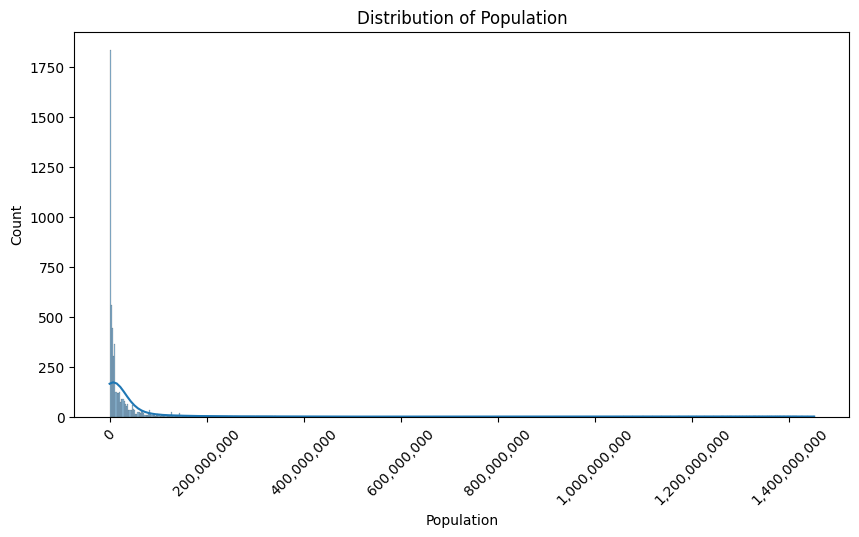

In [32]:
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 5))

sns.histplot(df["Population"], kde=True)

plt.title("Distribution of Population")
plt.xlabel("Population")

plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

plt.xticks(rotation=45)
plt.show()

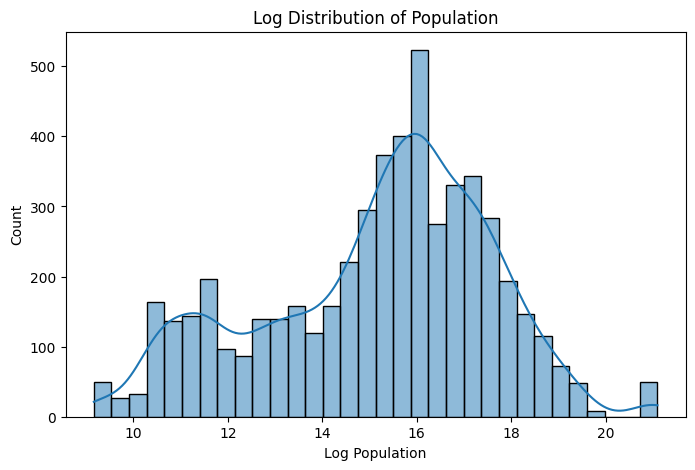

In [33]:
import numpy as np

plt.figure(figsize=(8, 5))

sns.histplot(np.log1p(df["Population"]), kde=True)

plt.title("Log Distribution of Population")
plt.xlabel("Log Population")

plt.show()

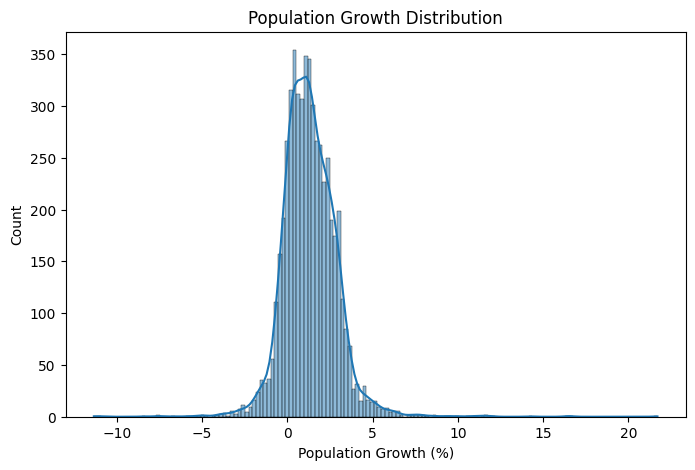

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Population_Growth"],
    kde=True
)

plt.title("Population Growth Distribution")
plt.xlabel("Population Growth (%)")

plt.show()

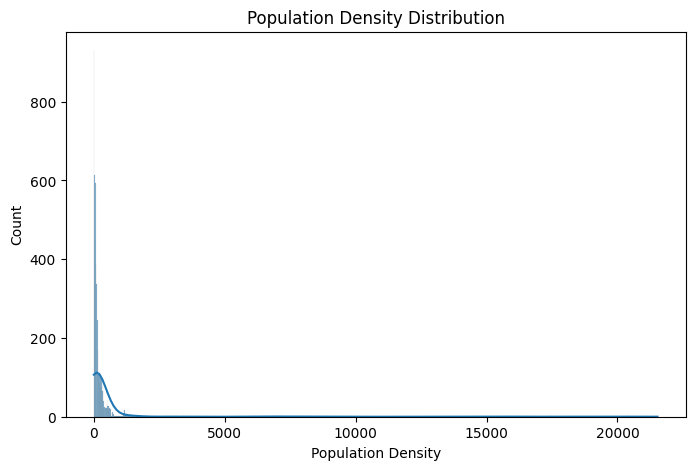

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Population_Density"],
    kde=True
)

plt.title("Population Density Distribution")
plt.xlabel("Population Density")

plt.show()

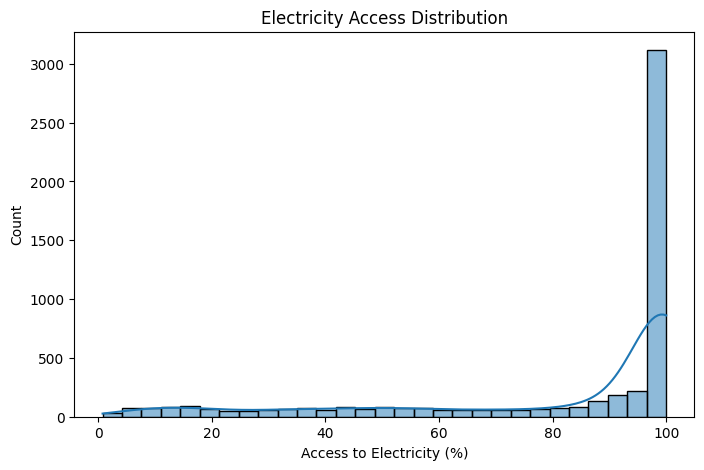

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Electricity_Access"],
    kde=True
)

plt.title("Electricity Access Distribution")
plt.xlabel("Access to Electricity (%)")

plt.show()

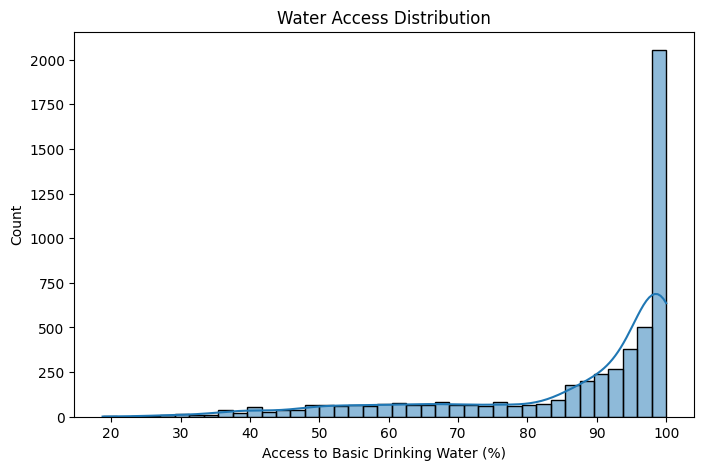

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Water_Access"],
    kde=True
)

plt.title("Water Access Distribution")
plt.xlabel("Access to Basic Drinking Water (%)")

plt.show()

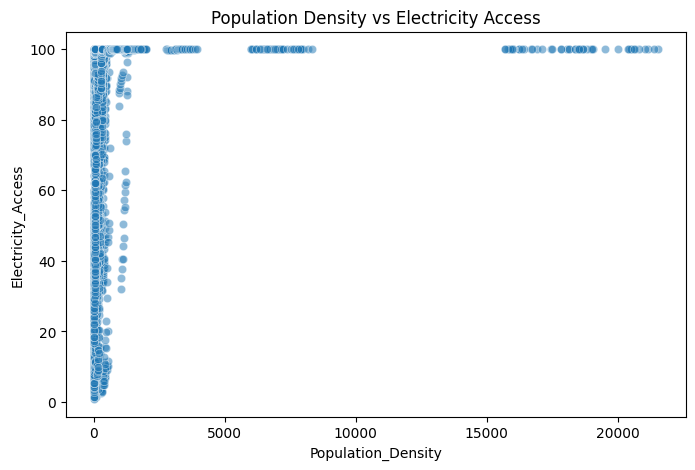

In [38]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Population_Density",
    y="Electricity_Access",
    alpha=0.5
)

plt.title("Population Density vs Electricity Access")

plt.show()

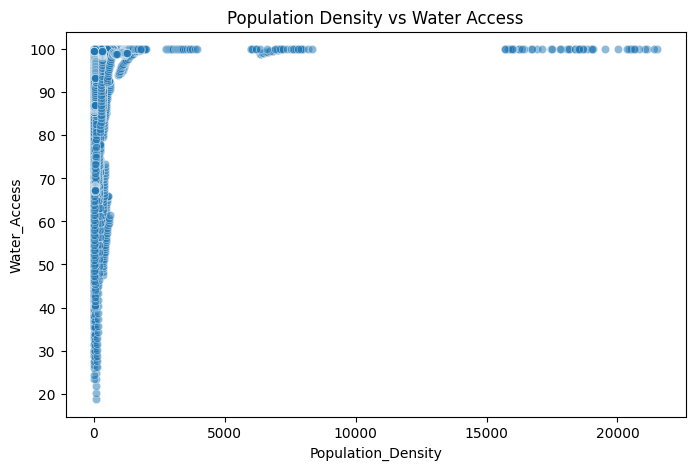

In [39]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Population_Density",
    y="Water_Access",
    alpha=0.5
)

plt.title("Population Density vs Water Access")

plt.show()

In [40]:
num_cols = [
    "Population",
    "Population_Growth",
    "Population_Density",
    "Urban_Population",
    "Electricity_Access",
    "Water_Access"
]

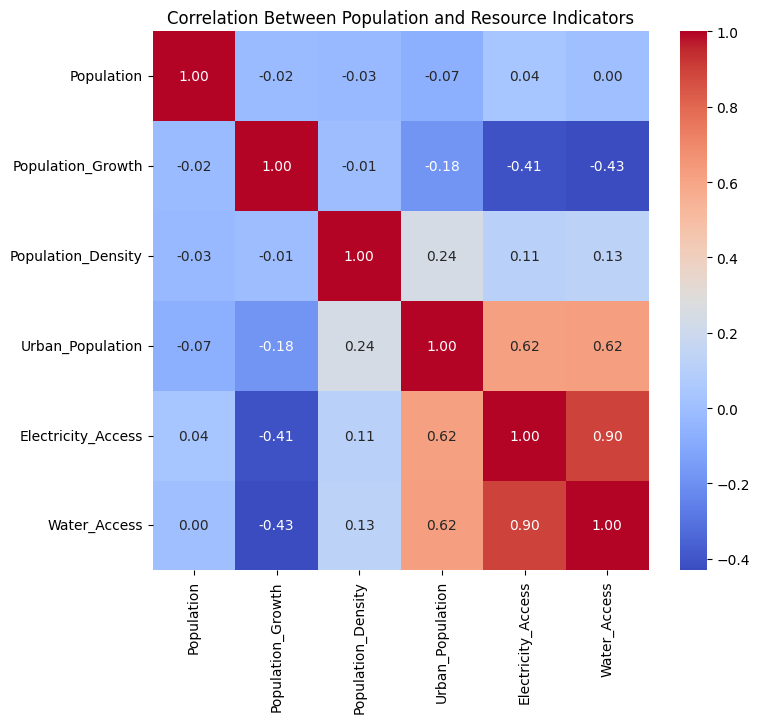

In [41]:
plt.figure(figsize=(8, 7))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Population and Resource Indicators")

plt.show()

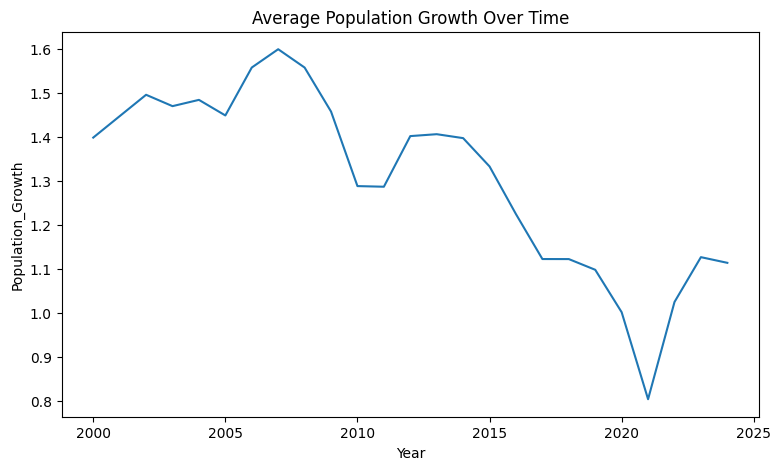

In [42]:
yearly_growth = (
    df.groupby("Year")["Population_Growth"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=yearly_growth,
    x="Year",
    y="Population_Growth"
)

plt.title("Average Population Growth Over Time")

plt.show()

**Practical 3: Probability Distribution Analysis**

In [43]:
from scipy import stats

In [44]:
pop_growth = df["Population_Growth"]

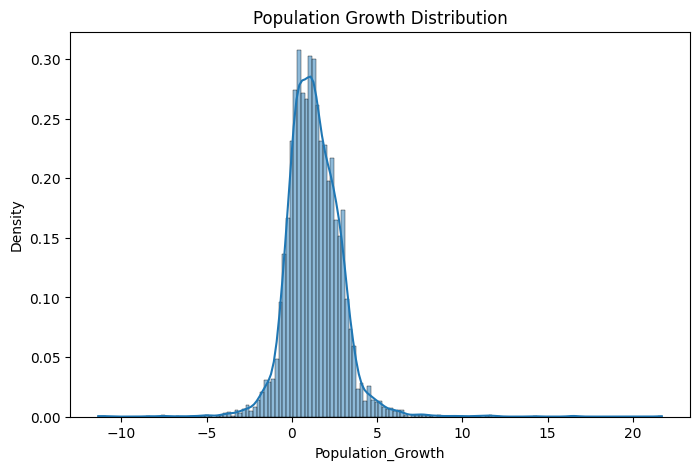

In [45]:
plt.figure(figsize=(8, 5))

sns.histplot(
    pop_growth,
    kde=True,
    stat="density"
)

plt.title("Population Growth Distribution")
plt.show()

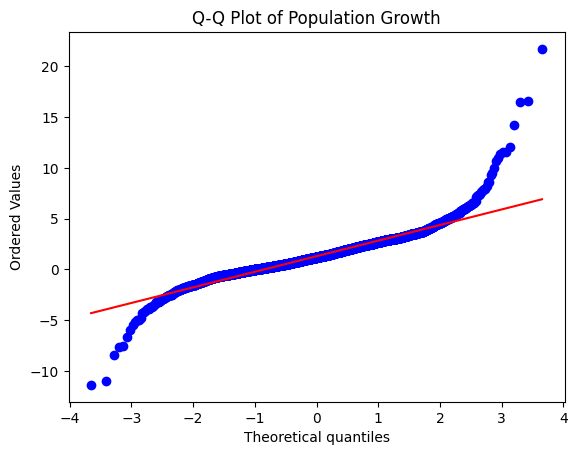

In [46]:
stats.probplot(
    pop_growth,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Population Growth")
plt.show()

In [47]:
random_sample = df.sample(
    frac=0.2,
    random_state=42
)

display(random_sample.head())

,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access,Region
1879,Greenland,GRL,2004,100.0,56898.0,0.138623,0.258691,82.563431,100.000000,Europe & Central Asia
5039,United Kingdom,GBR,2014,100.0,64619000.0,267.097921,0.747147,81.635575,100.000000,Europe & Central Asia
4420,Sri Lanka,LKA,2020,100.0,21919000.0,354.332363,0.530627,19.662190,89.302480,South Asia
3383,Nepal,NPL,2008,56.0,26990037.0,188.280691,0.749541,56.910806,84.550836,South Asia
555,Bolivia,BOL,2005,68.3,9360754.0,8.640962,1.685649,64.213306,84.155236,Latin America & Caribbean


In [48]:
systematic_sample = df.iloc[::100]

display(systematic_sample.head(10))

,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access,Region
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966,"Middle East, North Africa, Afghanistan & Pakistan"
100,Angola,AGO,2000,24.2,16194869.0,12.990189,3.312287,50.507065,37.842237,Sub-Saharan Africa
200,Aruba,ABW,2000,91.7,90588.0,503.266667,1.030817,65.354550,95.233536,Latin America & Caribbean
300,"Bahamas, The",BHS,2000,100.0,323835.0,32.351149,1.312011,81.036116,98.070593,Latin America & Caribbean
400,Belarus,BLR,2000,89.0,9979610.0,49.197478,-0.471131,69.917230,97.852313,Europe & Central Asia
500,Bermuda,BMU,2000,100.0,61550.0,1139.814815,0.694526,100.000000,100.000000,North America
600,Botswana,BWA,2000,26.5,1677382.0,2.959755,2.132106,53.204773,75.459566,Sub-Saharan Africa
700,Bulgaria,BGR,2000,88.1,8170172.0,73.851324,-0.493896,68.263145,99.737722,Europe & Central Asia
800,Cambodia,KHM,2000,16.6,12462336.0,70.600136,1.590170,18.624222,52.308235,East Asia & Pacific
900,Central African Republic,CAF,2000,6.0,3833416.0,6.153353,2.749554,37.701488,59.010489,Sub-Saharan Africa


In [49]:
sample_means = {
    "Population": df["Population_Growth"].mean(),
    "Random": random_sample["Population_Growth"].mean(),
    "Systematic": systematic_sample["Population_Growth"].mean()
}

sample_means

{'Population': np.float64(1.306913817172106),
 'Random': np.float64(1.3027358086408591),
 'Systematic': np.float64(1.269794611586936)}

**Practical 4: Central Limit Theorem**

In [50]:
pop_mean = pop_growth.mean()
pop_std = pop_growth.std()

In [51]:
means_5 = [
    pop_growth.sample(5, replace=True).mean()
    for _ in range(1000)
]

In [52]:
means_30 = [
    pop_growth.sample(30, replace=True).mean()
    for _ in range(1000)
]

In [53]:
means_100 = [
    pop_growth.sample(100, replace=True).mean()
    for _ in range(1000)
]

means_500 = [
    pop_growth.sample(500, replace=True).mean()
    for _ in range(1000)
]

In [54]:
sample_sets = {
    5: means_5,
    30: means_30,
    100: means_100,
    500: means_500
}

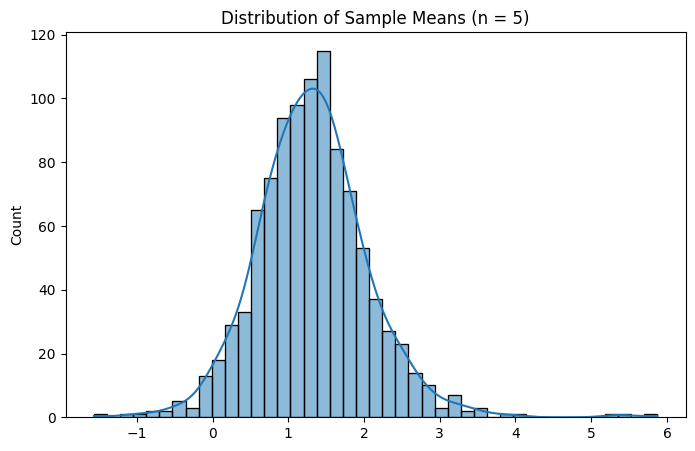

In [55]:
plt.figure(figsize=(8, 5))
sns.histplot(means_5, kde=True)
plt.title("Distribution of Sample Means (n = 5)")
plt.show()

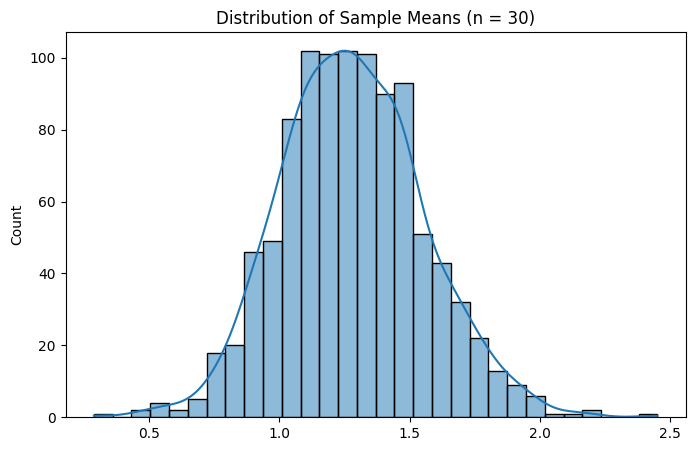

In [56]:
plt.figure(figsize=(8, 5))
sns.histplot(means_30, kde=True)
plt.title("Distribution of Sample Means (n = 30)")
plt.show()

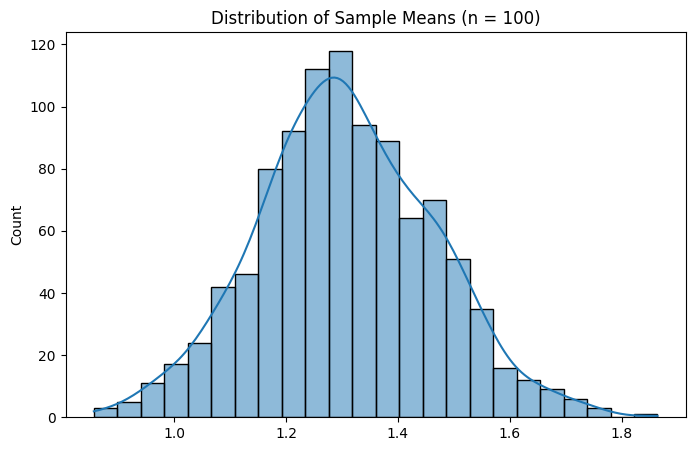

In [57]:
plt.figure(figsize=(8, 5))
sns.histplot(means_100, kde=True)
plt.title("Distribution of Sample Means (n = 100)")
plt.show()

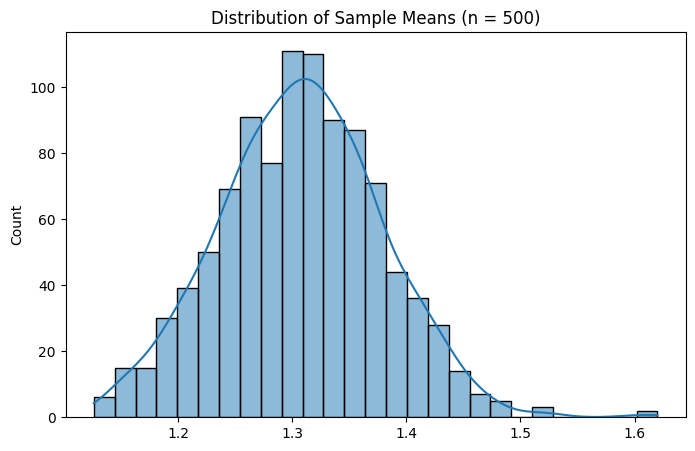

In [58]:
plt.figure(figsize=(8, 5))
sns.histplot(means_500, kde=True)
plt.title("Distribution of Sample Means (n = 500)")
plt.show()

In [59]:
import numpy as np

error_5 = pop_std / np.sqrt(5)
error_30 = pop_std / np.sqrt(30)
error_100 = pop_std / np.sqrt(100)
error_500 = pop_std / np.sqrt(500)

In [60]:
print("Estimated Error for n = 5:", error_5)
print("Estimated Error for n = 30:", error_30)
print("Estimated Error for n = 100:", error_100)
print("Estimated Error for n = 500:", error_500)

Estimated Error for n = 5: 0.7176861194543004
Estimated Error for n = 30: 0.2929941313568619
Estimated Error for n = 100: 0.160479494960785
Estimated Error for n = 500: 0.07176861194543004


PRACTICAL 5 ONWARDS

In [61]:
import numpy as np
import pandas as pd
from scipy import stats

from statsmodels.stats.weightstats import ztest

alpha = 0.05

pop_growth = df["Population_Growth"].dropna()

print("Sample size:", len(pop_growth))
print("Sample mean:", pop_growth.mean())
print("Sample standard deviation:", pop_growth.std())

Sample size: 5325
Sample mean: 1.306913817172106
Sample standard deviation: 1.60479494960785


In [62]:
chi_df = df.dropna(
    subset=["Region", "Population_Growth"]
).copy()

chi_df["Growth_Category"] = pd.qcut(
    chi_df["Population_Growth"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

contingency = pd.crosstab(
    chi_df["Region"],
    chi_df["Growth_Category"]
)

display(contingency)

Growth_Category,Low,Medium,High
Region,,,
East Asia & Pacific,334,389,177
Europe & Central Asia,881,401,118
Latin America & Caribbean,398,469,158
"Middle East, North Africa, Afghanistan & Pakistan",43,182,350
North America,30,42,3
South Asia,18,108,24
Sub-Saharan Africa,71,184,945


In [63]:
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if (expected < 5).any():
    print("Warning: Some expected cell counts are below 5.")

if p_value < alpha:
    print("Reject H0: Region and growth category are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

Chi-square statistic: 2383.3779066303086
Degrees of freedom: 12
P-value: 0.0
Reject H0: Region and growth category are associated.


In [64]:
num_cols = [
    "Population",
    "Population_Growth",
    "Population_Density",
    "Urban_Population",
    "Electricity_Access",
    "Water_Access"
]

cov_matrix = df[num_cols].cov()

display(cov_matrix.round(3))

,Population,Population_Growth,Population_Density,Urban_Population,Electricity_Access,Water_Access
Population,1.735702e+16,-4733868.322,-6.532039e+09,-2.226536e+08,1.369000e+08,6876835.306
Population_Growth,-4.733868e+06,2.575,-2.729400e+01,-7.086000e+00,-1.917900e+01,-12.186
Population_Density,-6.532039e+09,-27.294,3.566739e+06,1.111796e+04,5.838153e+03,4242.277
Urban_Population,-2.226536e+08,-7.086,1.111796e+04,5.814830e+02,4.288900e+02,265.331
Electricity_Access,1.369000e+08,-19.179,5.838153e+03,4.288900e+02,8.360380e+02,457.498
Water_Access,6.876835e+06,-12.186,4.242277e+03,2.653310e+02,4.574980e+02,310.531


In [65]:
pearson_corr = df[num_cols].corr(method="pearson")

display(pearson_corr.round(3))

,Population,Population_Growth,Population_Density,Urban_Population,Electricity_Access,Water_Access
Population,1.000,-0.022,-0.026,-0.070,0.036,0.003
Population_Growth,-0.022,1.000,-0.009,-0.183,-0.413,-0.431
Population_Density,-0.026,-0.009,1.000,0.244,0.107,0.127
Urban_Population,-0.070,-0.183,0.244,1.000,0.615,0.624
Electricity_Access,0.036,-0.413,0.107,0.615,1.000,0.898
Water_Access,0.003,-0.431,0.127,0.624,0.898,1.000


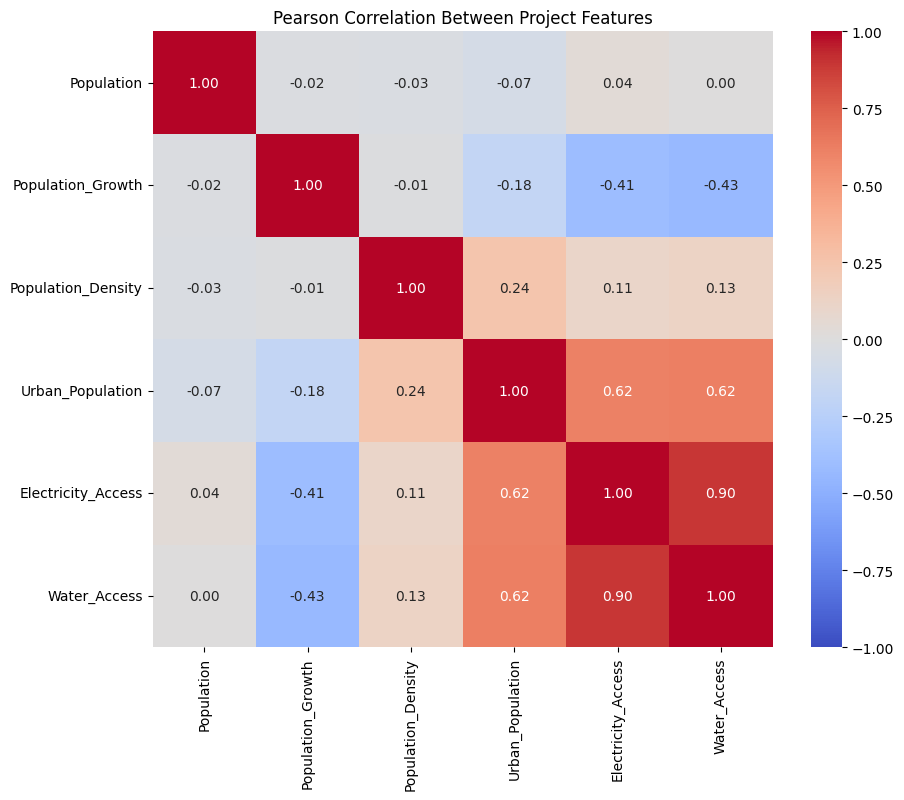

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Between Project Features")
plt.show()

In [67]:
spearman_corr = df[num_cols].corr(method="spearman")

display(spearman_corr.round(3))

,Population,Population_Growth,Population_Density,Urban_Population,Electricity_Access,Water_Access
Population,1.000,0.165,-0.154,-0.133,-0.202,-0.279
Population_Growth,0.165,1.000,-0.216,-0.261,-0.487,-0.479
Population_Density,-0.154,-0.216,1.000,0.157,0.268,0.325
Urban_Population,-0.133,-0.261,0.157,1.000,0.653,0.673
Electricity_Access,-0.202,-0.487,0.268,0.653,1.000,0.857
Water_Access,-0.279,-0.479,0.325,0.673,0.857,1.000


In [68]:
print("Pearson correlation:")
display(pearson_corr.round(3))

print("Spearman correlation:")
display(spearman_corr.round(3))

Pearson correlation:


,Population,Population_Growth,Population_Density,Urban_Population,Electricity_Access,Water_Access
Population,1.000,-0.022,-0.026,-0.070,0.036,0.003
Population_Growth,-0.022,1.000,-0.009,-0.183,-0.413,-0.431
Population_Density,-0.026,-0.009,1.000,0.244,0.107,0.127
Urban_Population,-0.070,-0.183,0.244,1.000,0.615,0.624
Electricity_Access,0.036,-0.413,0.107,0.615,1.000,0.898
Water_Access,0.003,-0.431,0.127,0.624,0.898,1.000


Spearman correlation:


,Population,Population_Growth,Population_Density,Urban_Population,Electricity_Access,Water_Access
Population,1.000,0.165,-0.154,-0.133,-0.202,-0.279
Population_Growth,0.165,1.000,-0.216,-0.261,-0.487,-0.479
Population_Density,-0.154,-0.216,1.000,0.157,0.268,0.325
Urban_Population,-0.133,-0.261,0.157,1.000,0.653,0.673
Electricity_Access,-0.202,-0.487,0.268,0.653,1.000,0.857
Water_Access,-0.279,-0.479,0.325,0.673,0.857,1.000


In [69]:
from itertools import combinations

results = []

for col1, col2 in combinations(num_cols, 2):
    pair = df[[col1, col2]].dropna()

    pearson_r, pearson_p = stats.pearsonr(
        pair[col1], pair[col2]
    )

    spearman_r, spearman_p = stats.spearmanr(
        pair[col1], pair[col2]
    )

    results.append({
        "Feature_1": col1,
        "Feature_2": col2,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_r,
        "Spearman_p": spearman_p,
        "N": len(pair)
    })

correlation_tests = pd.DataFrame(results)

display(
    correlation_tests.sort_values(
        "Pearson_p"
    ).round(4)
)

,Feature_1,Feature_2,Pearson_r,Pearson_p,Spearman_r,Spearman_p,N
14,Electricity_Access,Water_Access,0.8979,0.0000,0.8569,0.0,5325
12,Urban_Population,Electricity_Access,0.6151,0.0000,0.6528,0.0,5325
13,Urban_Population,Water_Access,0.6244,0.0000,0.6734,0.0,5325
8,Population_Growth,Water_Access,-0.4309,0.0000,-0.4790,0.0,5325
7,Population_Growth,Electricity_Access,-0.4133,0.0000,-0.4874,0.0,5325
9,Population_Density,Urban_Population,0.2441,0.0000,0.1574,0.0,5325
6,Population_Growth,Urban_Population,-0.1831,0.0000,-0.2607,0.0,5325
11,Population_Density,Water_Access,0.1275,0.0000,0.3247,0.0,5325
10,Population_Density,Electricity_Access,0.1069,0.0000,0.2678,0.0,5325
2,Population,Urban_Population,-0.0701,0.0000,-0.1335,0.0,5325


In [70]:
anova_df = df.dropna(
    subset=["Region", "Population_Growth"]
)

groups = [
    group["Population_Growth"].values
    for _, group in anova_df.groupby("Region")
    if len(group) > 1
]

f_stat, p_value = stats.f_oneway(*groups)

print("Number of groups:", len(groups))
print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < alpha:
    print("Reject H0: At least one regional mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Number of groups: 7
F-statistic: 360.36046670316756
P-value: 0.0
Reject H0: At least one regional mean differs.


PRACTICAL 7 ONWARDS

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [72]:
model_df = df.sort_values(
    ["Country", "Year"]
).copy()

# Create next-year target values for each country
future_columns = [
    "Population_Growth",
    "Electricity_Access",
    "Water_Access",
    "Population_Density",
    "Urban_Population",
    "Population"
]

for col in future_columns:
    model_df[col + "_Next_Year"] = (
        model_df.groupby("Country")[col].shift(-1)
    )

model_df["Target_Year"] = (
    model_df.groupby("Country")["Year"].shift(-1)
)

# Keep only records with the actual following calendar year
model_df = model_df[
    model_df["Target_Year"] == model_df["Year"] + 1
].copy()

model_df["Target_Year"] = model_df["Target_Year"].astype(int)

print("Modelling dataset shape:", model_df.shape)
print("Input years:", model_df["Year"].min(), "-", model_df["Year"].max())
print("Target years:", model_df["Target_Year"].min(), "-", model_df["Target_Year"].max())

display(model_df.head())

Modelling dataset shape: (5112, 17)
Input years: 2000 - 2023
Target years: 2001 - 2024


,Country,Country_Code,Year,Electricity_Access,Population,Population_Density,Population_Growth,Urban_Population,Water_Access,Region,Population_Growth_Next_Year,Electricity_Access_Next_Year,Water_Access_Next_Year,Population_Density_Next_Year,Urban_Population_Next_Year,Population_Next_Year,Target_Year
0,Afghanistan,AFG,2000,4.4,20130327.0,30.863847,1.212176,18.558200,29.730966,"Middle East, North Africa, Afghanistan & Pakistan",0.762005,9.3,29.762926,31.099929,18.741238,20284307.0,2001
1,Afghanistan,AFG,2001,9.3,20284307.0,31.099929,0.762005,18.741238,29.762926,"Middle East, North Africa, Afghanistan & Pakistan",5.252030,14.1,31.836077,32.776961,18.941248,21378117.0,2002
2,Afghanistan,AFG,2002,14.1,21378117.0,32.776961,5.252030,18.941248,31.836077,"Middle East, North Africa, Afghanistan & Pakistan",6.145194,19.0,33.908629,34.854344,19.160035,22733049.0,2003
3,Afghanistan,AFG,2003,19.0,22733049.0,34.854344,6.145194,19.160035,33.908629,"Middle East, North Africa, Afghanistan & Pakistan",3.575835,23.8,35.999355,36.123230,19.399359,23560654.0,2004
4,Afghanistan,AFG,2004,23.8,23560654.0,36.123230,3.575835,19.399359,35.999355,"Middle East, North Africa, Afghanistan & Pakistan",3.519217,28.7,38.108054,37.417118,19.705910,24404567.0,2005


In [73]:
# Classification targets for next-year electricity and water access
access_bins = [-np.inf, 50, 80, np.inf]
access_labels = ["Low", "Moderate", "High"]

model_df["Electricity_Access_Level_Next_Year"] = pd.cut(
    model_df["Electricity_Access_Next_Year"],
    bins=access_bins,
    labels=access_labels,
    right=False
)

model_df["Water_Access_Level_Next_Year"] = pd.cut(
    model_df["Water_Access_Next_Year"],
    bins=access_bins,
    labels=access_labels,
    right=False
)

# Build a relative resource-pressure index
# Higher population, density, urbanization, and lower access
# contribute to a higher index.

pressure_components = pd.DataFrame(index=model_df.index)

pressure_components["Population"] = np.log1p(
    model_df["Population_Next_Year"].clip(lower=0)
).rank(pct=True)

pressure_components["Density"] = np.log1p(
    model_df["Population_Density_Next_Year"].clip(lower=0)
).rank(pct=True)

pressure_components["Urbanization"] = (
    model_df["Urban_Population_Next_Year"].rank(pct=True)
)

pressure_components["Limited_Electricity_Access"] = (
    (100 - model_df["Electricity_Access_Next_Year"]).rank(pct=True)
)

pressure_components["Limited_Water_Access"] = (
    (100 - model_df["Water_Access_Next_Year"]).rank(pct=True)
)

model_df["Resource_Pressure_Index_Next_Year"] = (
    pressure_components.mean(axis=1)
)

# Divide the index into three approximately equal-sized groups
pressure_ranks = model_df[
    "Resource_Pressure_Index_Next_Year"
].rank(method="first")

model_df["Resource_Pressure_Level_Next_Year"] = pd.qcut(
    pressure_ranks,
    q=3,
    labels=["Low", "Moderate", "High"]
)

print("Classification targets created.")

Classification targets created.


In [74]:
target_columns = [
    "Electricity_Access_Level_Next_Year",
    "Water_Access_Level_Next_Year",
    "Resource_Pressure_Level_Next_Year"
]

for target in target_columns:
    print("\n", target)
    display(
        model_df[target]
        .value_counts()
        .reindex(["Low", "Moderate", "High"])
        .to_frame("Count")
    )


 Electricity_Access_Level_Next_Year


,Count
Electricity_Access_Level_Next_Year,
Low,893
Moderate,546
High,3673



 Water_Access_Level_Next_Year


,Count
Water_Access_Level_Next_Year,
Low,305
Moderate,930
High,3877



 Resource_Pressure_Level_Next_Year


,Count
Resource_Pressure_Level_Next_Year,
Low,1704
Moderate,1704
High,1704


In [75]:
feature_cols = [
    "Population",
    "Population_Growth",
    "Population_Density",
    "Urban_Population",
    "Electricity_Access",
    "Water_Access",
    "Year"
]

regression_target = "Population_Growth_Next_Year"

model_df = model_df.dropna(
    subset=feature_cols + [
        regression_target,
        "Electricity_Access_Level_Next_Year",
        "Water_Access_Level_Next_Year",
        "Resource_Pressure_Level_Next_Year"
    ]
).copy()

print("Final modelling records:", len(model_df))
print("Input features:", feature_cols)
print("Regression target:", regression_target)

Final modelling records: 5112
Input features: ['Population', 'Population_Growth', 'Population_Density', 'Urban_Population', 'Electricity_Access', 'Water_Access', 'Year']
Regression target: Population_Growth_Next_Year


In [76]:
train_df = model_df[model_df["Target_Year"] <= 2014].copy()

val_df = model_df[
    model_df["Target_Year"].between(2015, 2021)
].copy()

test_df = model_df[
    model_df["Target_Year"].between(2022, 2024)
].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining target years:",
      train_df["Target_Year"].min(), "-", train_df["Target_Year"].max())

print("Validation target years:",
      val_df["Target_Year"].min(), "-", val_df["Target_Year"].max())

print("Testing target years:",
      test_df["Target_Year"].min(), "-", test_df["Target_Year"].max())

Training records: 2982
Validation records: 1491
Testing records: 639

Training target years: 2001 - 2014
Validation target years: 2015 - 2021
Testing target years: 2022 - 2024


In [77]:
X_train = train_df[feature_cols]
y_train = train_df[regression_target]

X_val = val_df[feature_cols]
y_val = val_df[regression_target]

regression_models = {
    "Simple Linear Regression": (
        LinearRegression(),
        ["Population_Growth"]
    ),

    "Multiple Linear Regression": (
        LinearRegression(),
        feature_cols
    ),

    "Ridge Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0))
        ]),
        feature_cols
    ),

    "Lasso Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Lasso(alpha=0.01, max_iter=10000))
        ]),
        feature_cols
    ),

    "Decision Tree Regressor": (
        DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=5,
            random_state=42
        ),
        feature_cols
    ),

    "Random Forest Regressor": (
        RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),
        feature_cols
    )
}

regression_results = []

for name, (model, used_features) in regression_models.items():

    model.fit(
        train_df[used_features],
        y_train
    )

    predictions = model.predict(
        val_df[used_features]
    )

    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2 Score": r2_score(y_val, predictions)
    })

regression_results = pd.DataFrame(regression_results)

display(
    regression_results.sort_values("RMSE").round(4)
)

,Model,MAE,RMSE,R2 Score
2,Ridge Regression,0.3009,0.7887,0.7169
1,Multiple Linear Regression,0.3007,0.7887,0.7168
3,Lasso Regression,0.3036,0.7891,0.7165
0,Simple Linear Regression,0.3157,0.8014,0.7076
5,Random Forest Regressor,0.3348,0.8824,0.6456
4,Decision Tree Regressor,0.4300,0.9705,0.5713


In [78]:
best_reg_name = (
    regression_results
    .sort_values("RMSE")
    .iloc[0]["Model"]
)

best_reg_model, best_reg_features = regression_models[
    best_reg_name
]

print("Selected model:", best_reg_name)
print("Features used:", best_reg_features)

# Refit using training + validation records
train_val_df = pd.concat(
    [train_df, val_df]
).sort_values("Target_Year")

best_reg_model.fit(
    train_val_df[best_reg_features],
    train_val_df[regression_target]
)

# Evaluate once on the untouched test period
X_test_reg = test_df[best_reg_features]
y_test_reg = test_df[regression_target]

test_predictions = best_reg_model.predict(X_test_reg)

print("\nFinal Test Results")
print("MAE:", round(mean_absolute_error(y_test_reg, test_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, test_predictions)), 4))
print("R2 Score:", round(r2_score(y_test_reg, test_predictions), 4))

Selected model: Ridge Regression
Features used: ['Population', 'Population_Growth', 'Population_Density', 'Urban_Population', 'Electricity_Access', 'Water_Access', 'Year']

Final Test Results
MAE: 0.4284
RMSE: 1.0971
R2 Score: 0.4597


,Actual Growth,Predicted Growth
0,1.435704,2.063229
1,2.135594,1.303037
2,2.836573,1.865417
3,-1.543157,-1.246246
4,-1.644108,-1.253675
5,-1.442144,-1.344808
6,1.587582,1.408259
7,1.498976,1.374138
8,1.398387,1.293268
9,1.696768,1.090318


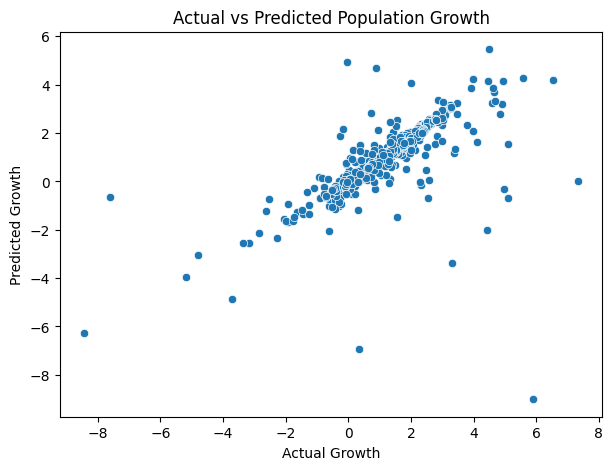

In [79]:
regression_comparison = pd.DataFrame({
    "Actual Growth": y_test_reg.values,
    "Predicted Growth": test_predictions
})

display(regression_comparison.head(15))

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=regression_comparison,
    x="Actual Growth",
    y="Predicted Growth"
)

plt.title("Actual vs Predicted Population Growth")
plt.show()

In [80]:
def train_classifier(target_col, file_name):

    X_train = train_df[feature_cols]
    y_train = train_df[target_col]

    X_val = val_df[feature_cols]
    y_val = val_df[target_col]

    classifiers = {
        "Decision Tree Classifier": DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42
        ),

        "Random Forest Classifier": RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    }

    results = []

    # Compare models on validation data
    for name, model in classifiers.items():

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Weighted F1": f1_score(
                y_val, predictions, average="weighted"
            )
        })

    results_df = pd.DataFrame(results).sort_values(
        "Weighted F1",
        ascending=False
    )

    display(results_df.round(4))

    best_name = results_df.iloc[0]["Model"]
    best_model = classifiers[best_name]

    # Refit the selected model on training + validation data
    train_val_X = pd.concat([
        train_df[feature_cols],
        val_df[feature_cols]
    ])

    train_val_y = pd.concat([
        train_df[target_col],
        val_df[target_col]
    ])

    best_model.fit(train_val_X, train_val_y)

    # Final evaluation on test data
    y_test = test_df[target_col]
    test_predictions = best_model.predict(
        test_df[feature_cols]
    )

    print("\nTarget:", target_col)
    print("Selected model:", best_name)
    print("\nTest Accuracy:",
          round(accuracy_score(y_test, test_predictions), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        test_predictions,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions
    )

    plt.title("Confusion Matrix: " + target_col)
    plt.show()

    # Save the selected model and its input columns
    joblib.dump(
        {
            "model": best_model,
            "features": feature_cols,
            "target": target_col
        },
        file_name
    )

    print("Model saved to:", file_name)

    return best_model, results_df

,Model,Accuracy,Weighted F1
1,Random Forest Classifier,0.9846,0.9847
0,Decision Tree Classifier,0.9712,0.9720



Target: Electricity_Access_Level_Next_Year
Selected model: Random Forest Classifier

Test Accuracy: 0.9797

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.99      0.99       500
         Low       0.91      0.98      0.94        52
    Moderate       0.92      0.93      0.93        87

    accuracy                           0.98       639
   macro avg       0.94      0.97      0.95       639
weighted avg       0.98      0.98      0.98       639



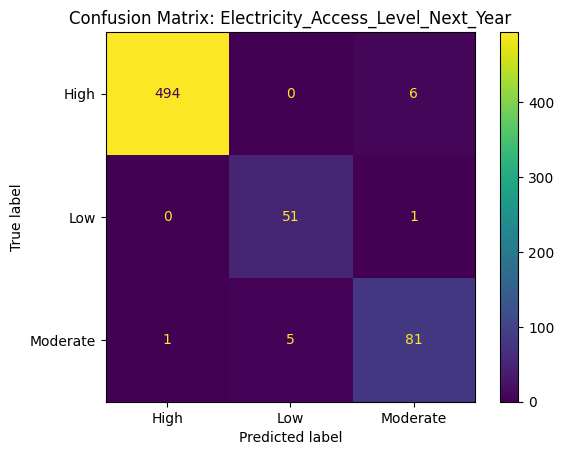

Model saved to: electricity_access_classifier.joblib


In [81]:
electricity_model, electricity_results = train_classifier(
    target_col="Electricity_Access_Level_Next_Year",
    file_name="electricity_access_classifier.joblib"
)

,Model,Accuracy,Weighted F1
0,Decision Tree Classifier,0.9960,0.9960
1,Random Forest Classifier,0.9933,0.9933



Target: Water_Access_Level_Next_Year
Selected model: Decision Tree Classifier

Test Accuracy: 0.989

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.99      1.00       514
         Low       0.92      0.80      0.86        15
    Moderate       0.95      0.99      0.97       110

    accuracy                           0.99       639
   macro avg       0.96      0.93      0.94       639
weighted avg       0.99      0.99      0.99       639



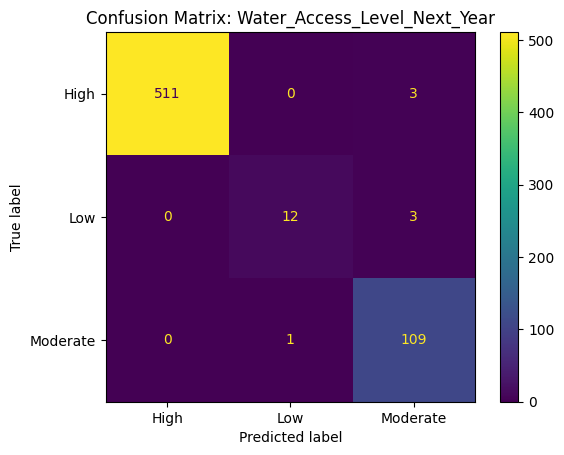

Model saved to: water_access_classifier.joblib


In [82]:
water_model, water_results = train_classifier(
    target_col="Water_Access_Level_Next_Year",
    file_name="water_access_classifier.joblib"
)

,Model,Accuracy,Weighted F1
1,Random Forest Classifier,0.8994,0.9002
0,Decision Tree Classifier,0.8404,0.8403



Target: Resource_Pressure_Level_Next_Year
Selected model: Random Forest Classifier

Test Accuracy: 0.9343

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.93      0.93       195
         Low       0.97      0.96      0.97       248
    Moderate       0.89      0.90      0.89       196

    accuracy                           0.93       639
   macro avg       0.93      0.93      0.93       639
weighted avg       0.93      0.93      0.93       639



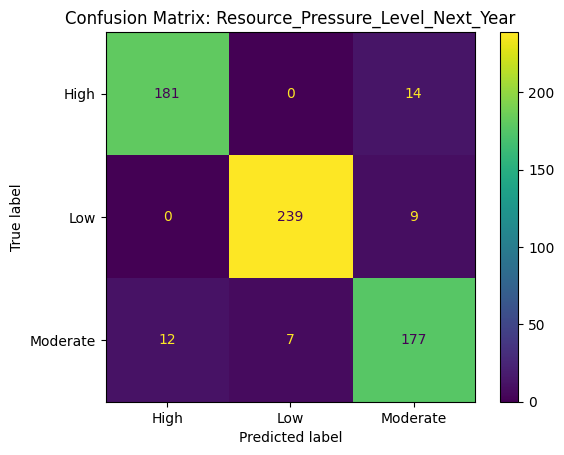

Model saved to: resource_pressure_classifier.joblib


In [83]:
pressure_model, pressure_results = train_classifier(
    target_col="Resource_Pressure_Level_Next_Year",
    file_name="resource_pressure_classifier.joblib"
)

STREAMLIT

In [96]:
!pip install -q -r /content/requirements.txt

In [97]:
!streamlit run /content/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    > /content/streamlit.log 2>&1 &

In [98]:
!sleep 3
!cat /content/streamlit.log
!curl -I http://127.0.0.1:8501



2026-10-28 05:54:34.623 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.253.217.165:8501

HTTP/1.1 200 OK
date: Wed, 28 Oct 2026 05:54:34 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Wed, 28 Oct 2026 05:53:35 GMT
etag: "0fe8fc4bdaf6c7e638ad7e6ac42116eb"
cache-control: no-cache



In [99]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501, "http")
print("Updated app:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-28T05:54:37+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-28T05:54:37+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [93]:
!pip install -q pyngrok

In [95]:
!pkill -f streamlit || true

^C


In [100]:
!pip install -q pyngrok

In [101]:
from pyngrok import ngrok

ngrok.kill()

ngrok.set_auth_token("3KxK2Imv1A0rbSvAlVCn6VqvqKi_2ZumXjCpoqzMJFGLFnuEt")

In [102]:
public_url = ngrok.connect(8501, "http")

print("Updated app:", public_url)

Updated app: NgrokTunnel: "https://little-dad-earful.ngrok-free.dev" -> "http://localhost:8501"
